# Part 1 · Foundations

**Qubits · quantum states · measurement · entanglement.**

Quantum computing uses quantum-mechanical effects to store and process information. Its unit is the **qubit**, whose state holds an amplitude for 0 and an amplitude for 1; measuring it still gives a single bit.

Simulating molecules and materials is used in drug discovery and battery design, but the memory needed to describe their quantum behavior can grow rapidly with their size. Searching for good schedules, routes, or portfolios can also become computationally expensive as the number of choices grows. These problems motivate the search for quantum algorithms.

Machine learning is another candidate application. A circuit can act as a model whose gate angles are trained like the weights of a neural network. In a quantum reservoir, a fixed quantum system processes a time series and only a classical readout is trained. Qilimanjaro works on reservoirs for forecasting. Whether these approaches beat classical models on ordinary data such as images or tables is still an open research question.

Quantum measurements have other applications, including random number generation and communication protocols that can reveal eavesdropping. This notebook builds the vocabulary behind those applications.

We treat quantum states as **mathematical objects** that you construct and inspect directly with NumPy and QiliSDK. Circuits and simulation come in Part 2. By the end, you will be able to:

- describe a qubit's state as a vector of complex **amplitudes**;
- predict measurement outcomes using the **Born rule**;
- construct states with **superposition** and **entanglement**.

You need Python and some linear algebra: vectors, matrices, and complex numbers. Section 1.1 recalls the complex-number basics we use. No quantum-computing knowledge is assumed. Run the cells in order, starting with the installation cell below. The examples use QiliSDK 0.3.0; an existing installation is left unchanged, so check the version it prints.

### How QiliSDK is organized

QiliSDK separates a computation into three layers:

1. **Primitives** describe its ingredients. `QTensor` holds state vectors and operators (matrices acting on states); `Gate` and `Circuit` describe digital operations. For analog computing, `Hamiltonian` describes a system's energy and `Schedule` describes how it changes over time. `Readout` specifies what to measure.
2. **Functionals** describe computations built from those ingredients. Examples are `DigitalPropagation` for a circuit, `AnalogEvolution` for an analog schedule, and `VariationalProgram` for a computation whose parameters are optimized.
3. **Backends** execute computations. `QiliSim`, the C++ simulator that ships with QiliSDK, is the one we use. Optional backends include `CudaqBackend` for NVIDIA GPUs and `QutipBackend`, built on QuTiP. Quantum processing units (**QPUs**) are reached through a separate cloud client, `SpeQtrum`.

Part 1 uses `QTensor` directly. Circuits and execution on `QiliSim` follow in Part 2.

In [ ]:
# Run me first: install QiliSDK if missing, then display its version.
try:
    import qilisdk
except ImportError:
    import sys
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "qilisdk==0.3.0"], check=True)
    # Colab: if this import fails, restart the session and rerun from the top.
    import qilisdk
print(qilisdk.__version__)

In [ ]:
import numpy as np

from qilisdk.core import QTensor, ket, bra, ghz, tensor_prod

## 1.1 · Qubits and quantum states

A **classical bit** is either $0$ or $1$. A **qubit** is a physical system with two distinguishable states that we label $0$ and $1$. The two states can be two energy levels of a small superconducting circuit cooled close to absolute zero, as in Qilimanjaro's processors, or two levels of a trapped ion. We describe a qubit using a **pure state**, a normalized vector of two complex numbers called **amplitudes**. In NumPy, this could be `v = np.array([alpha, beta], dtype=complex)`, with `np.sum(np.abs(v)**2) == 1` mathematically, allowing for floating-point rounding in code. Pure states are the states described by a single vector. Noise turns them into **mixed** states, which need a matrix instead; this tutorial uses pure states only.

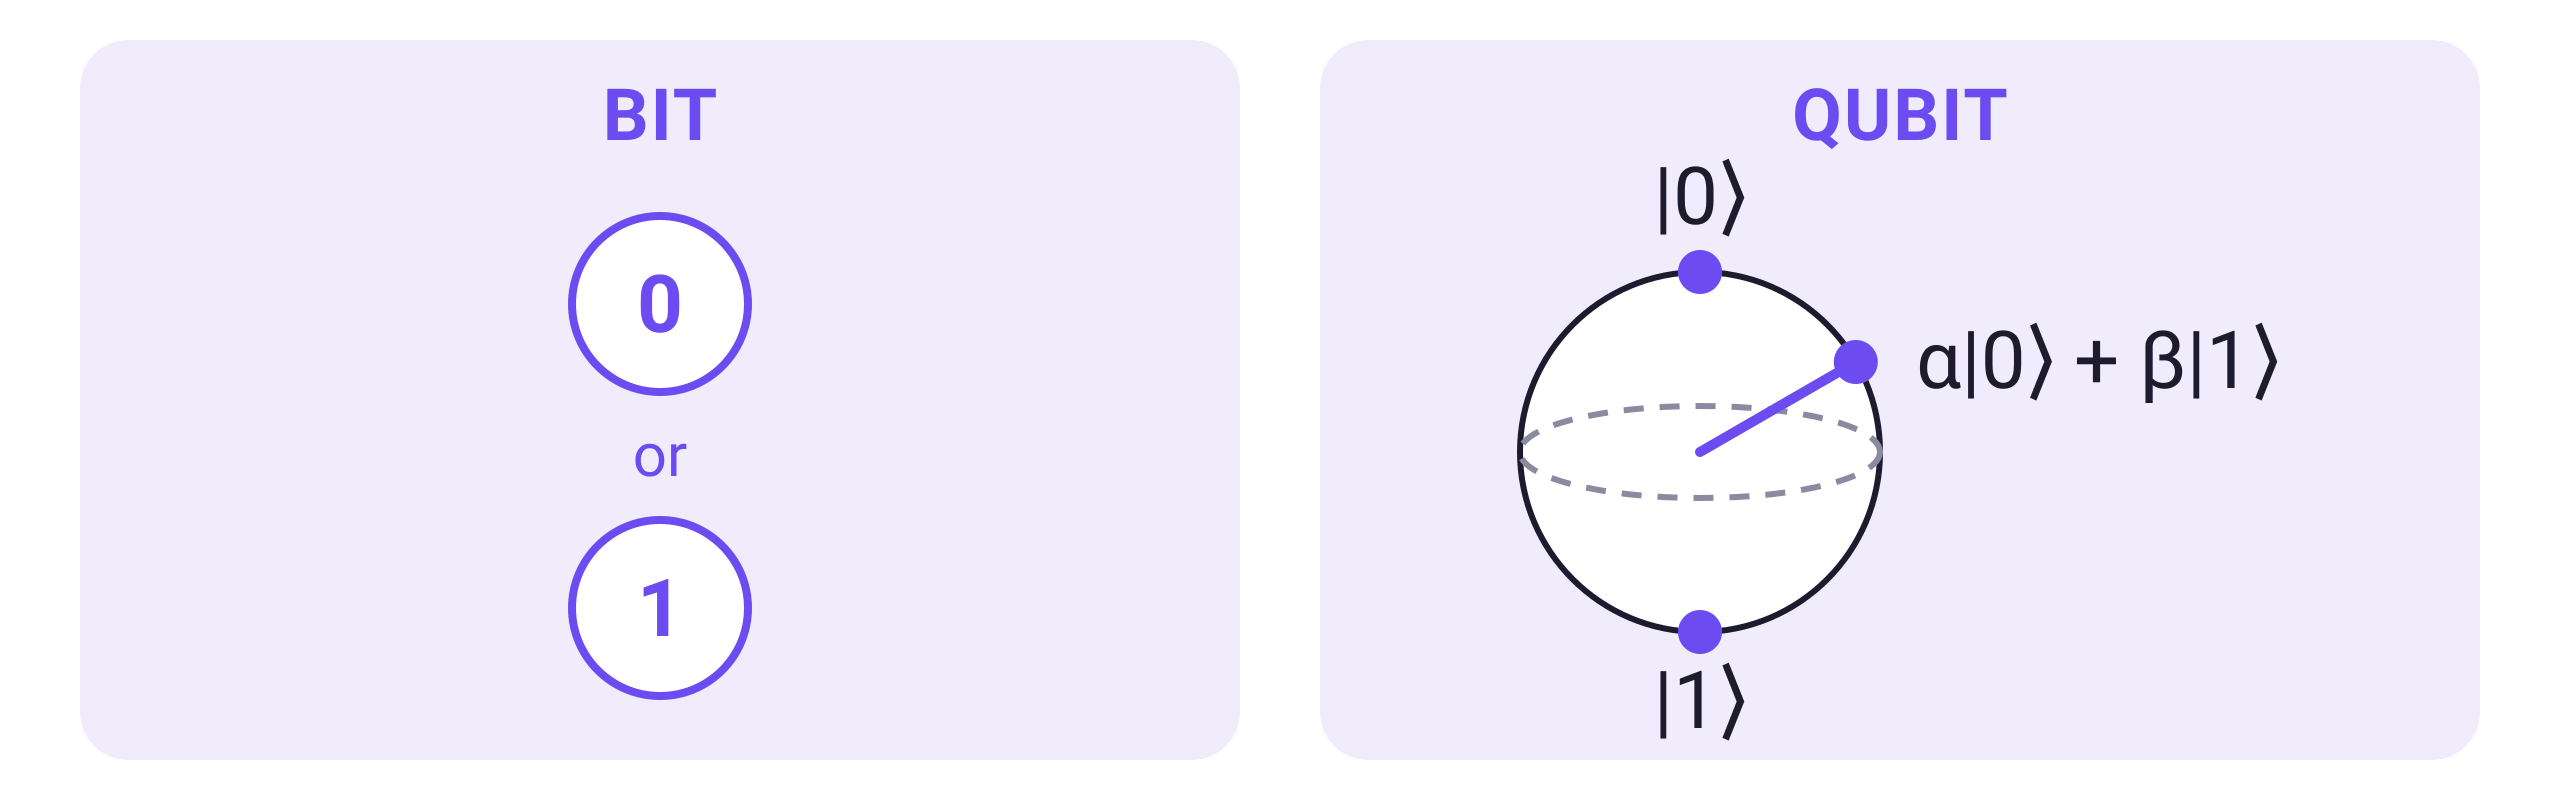

In **Dirac notation**, also called bra-ket notation, $|\psi\rangle$ (read "ket psi") denotes the state vector. The **basis states** $|0\rangle$ and $|1\rangle$ form the **computational basis**, the measurement basis used throughout this notebook. They are column vectors:

$$|0\rangle = \begin{pmatrix}1\\0\end{pmatrix},\qquad |1\rangle = \begin{pmatrix}0\\1\end{pmatrix}.$$

The amplitudes $\alpha$ and $\beta$ are the coefficients of these basis states. Writing $\mathbb{C}$ for the complex numbers, a qubit state has the form

$$|\psi\rangle = \alpha\,|0\rangle + \beta\,|1\rangle,\qquad \alpha,\beta\in\mathbb{C},\qquad |\alpha|^2 + |\beta|^2 = 1.$$

The **Born rule** gives the probability of each measurement outcome as the squared magnitude of its amplitude. Normalization therefore makes the probabilities sum to one. Section 1.2 shows how to calculate and sample them.

A **ket** is represented as a column vector with shape `(2, 1)`. Its **bra**, $\langle\psi|$, is the conjugate transpose, a row with shape `(1, 2)`: `state.conj().T` for a NumPy array, or `state.dagger()` for a `QTensor`. Complex conjugation changes $a+bi$ to $a-bi$; the dagger symbol $\dagger$ denotes the conjugate transpose.

QiliSDK's **`QTensor`** represents both states and operators. `ket(0)` creates $|0\rangle$, `ket(1)` creates $|1\rangle$, and `bra(0)` creates $\langle 0| = |0\rangle^\dagger$. Printing a `QTensor` shows its shape and its amplitudes, one per line, as (real, imaginary) pairs; `nnz` is the number of nonzero entries.

In [ ]:
state = ket(0)
print(state)

# One qubit, stored as a ket (a column vector)
print(state.nqubits, state.is_ket())

### Combining qubits: the tensor product

Two qubits have a joint state in a four-dimensional space with basis $|00\rangle, |01\rangle, |10\rangle, |11\rangle$. If they have separate state vectors $[a_0, a_1]$ and $[b_0, b_1]$, their **tensor product**, written $\otimes$, has amplitudes $[a_0 b_0,\; a_0 b_1,\; a_1 b_0,\; a_1 b_1]$. Each entry describes one combination of the qubits' values. NumPy computes this product with `np.kron(A, B)`. Not every joint state can be factored this way; section 1.3 introduces entanglement.

Each additional qubit doubles the number of basis states, so an $n$-qubit state vector contains $2^n$ complex amplitudes. QiliSDK uses **big-endian** ordering: in `ket(a, b)`, the first argument is the most-significant bit. Thus `ket(0, 1)` represents $|01\rangle$, at index $1$ in the four-entry vector, since binary `01` equals 1.

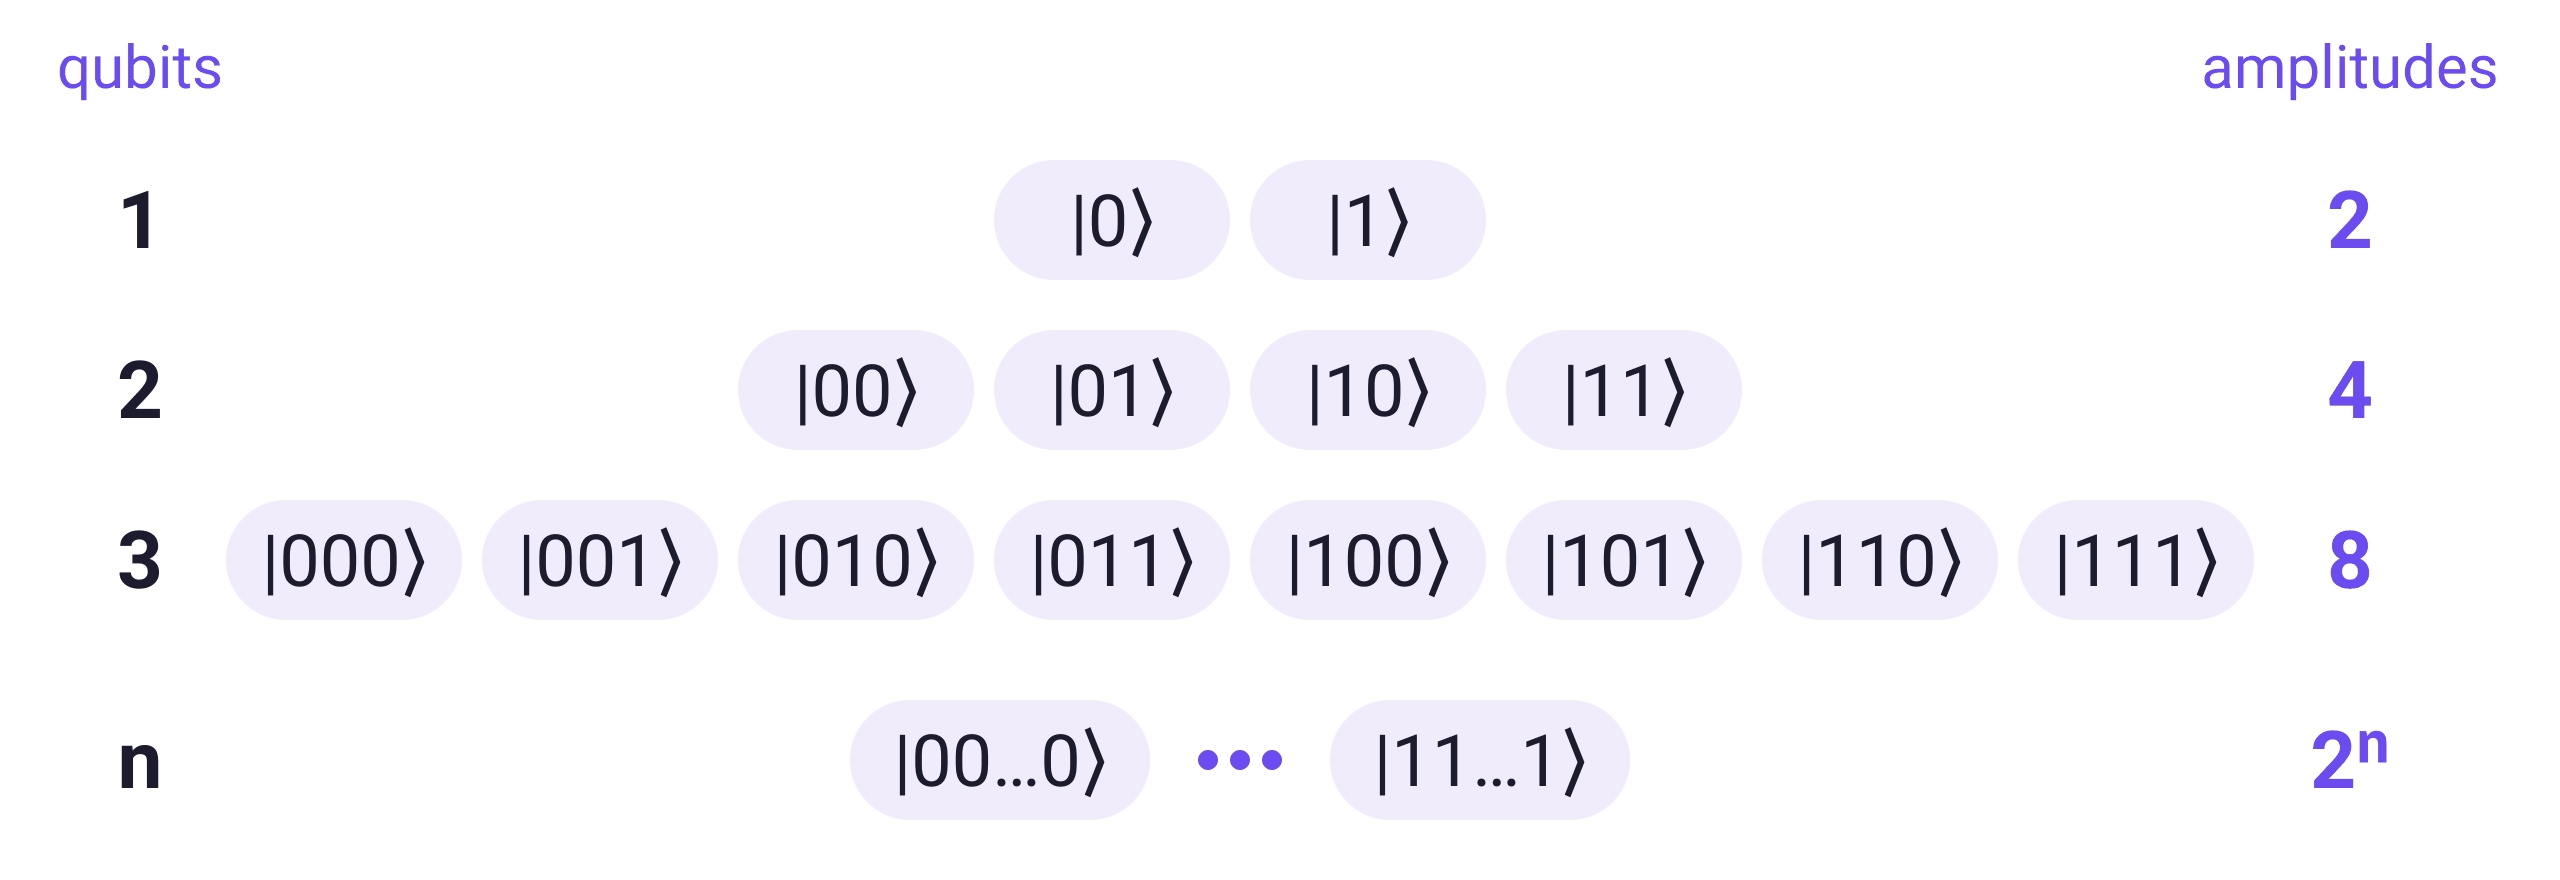

In [ ]:
# The 2-qubit state |01>: its one nonzero amplitude is at index 1, binary 01
state_01 = ket(0, 1)
print(state_01)

# A bra is the conjugate transpose: a row vector
bra_0 = bra(0)
print(bra_0)

### The memory cost of $2^n$ amplitudes

A general state-vector simulation stores $2^n$ amplitudes for $n$ qubits. Each added qubit doubles the memory needed, so even a modest increase in system size can put the simulation beyond a classical computer's capacity. Yet a physical quantum system evolves without storing those numbers in an array. This motivated Richard Feynman's 1982 proposal: to simulate a quantum system, build hardware that is itself quantum and represents the state physically.

The next cell calculates the storage needed for a dense state vector using `complex128`, which takes 16 bytes per amplitude. It allocates arrays for the smaller examples, then extrapolates the larger ones with Python arithmetic.

In [ ]:
# QTensor.zero(nqubits) is the state |00...0>. Its .dense() array holds 2**nqubits amplitudes,
# stored as complex128 numbers of 16 bytes each.
for nqubits in [1, 2, 4, 8, 12, 20]:
    memory = QTensor.zero(nqubits).dense().nbytes
    print(nqubits, "qubits:", memory, "bytes")

# Larger states would not fit in memory, so we just do the arithmetic.
# 33 qubits: a very large workstation
memory_33_qubits = 16 * 2**33 / 1e9
print(memory_33_qubits, "GB")

# 50 qubits: more than the total memory of the Frontier supercomputer
memory_50_qubits = 16 * 2**50 / 1e15
print(memory_50_qubits, "PB")

# 280 qubits: more bytes than the ~1e80 atoms in the observable universe
memory_280_qubits = 16 * 2.0**280
print(memory_280_qubits, "bytes")

### Measurement and superposition

An $n$-qubit state has $2^n$ amplitudes, but measuring all its qubits in the computational basis returns one $n$-bit outcome. It does not reveal the amplitude vector. After that measurement, the state has collapsed to the observed basis state. Quantum algorithms can use **interference**, the addition or cancellation of amplitudes, to change which outcomes are likely before measurement.

Whatever we measure, $n$ qubits can never yield more than $n$ bits of classical information (Holevo's bound). The $2^n$ amplitudes make quantum systems hard to simulate, but a quantum computer does not try every answer and report the best one. It helps only when an algorithm can make the amplitudes of wrong answers cancel.

A **superposition** has more than one nonzero amplitude in the chosen basis. Two useful single-qubit examples are the **plus** and **minus** states:

$$|+\rangle = \tfrac{1}{\sqrt{2}}\big(|0\rangle + |1\rangle\big),\qquad |-\rangle = \tfrac{1}{\sqrt{2}}\big(|0\rangle - |1\rangle\big).$$

Both amplitudes have magnitude $1/\sqrt 2$, so both states give $0$ and $1$ with probability $\tfrac12$ in the **computational basis**, $\{|0\rangle, |1\rangle\}$. This is also called the **$Z$ basis**, after the vertical axis of the Bloch sphere in the next section. The states differ in the sign of their second amplitude, an example of a **relative phase**. More generally, phase is the angle of a complex amplitude, and relative phase is the difference between two such angles. Python has complex numbers built in: for `z = 0.6 + 0.8j`, `abs(z)` gives the magnitude, 1.0, and `cmath.phase(z)` gives the angle in radians. A **phase factor** $e^{i\varphi}$ has magnitude 1 and angle $\varphi$; for example, $e^{i\pi} = -1$. When gates recombine amplitudes, opposite signs can cause cancellation. Part 2 demonstrates this effect.

Multiplying every amplitude by the same unit-magnitude factor changes only the **global phase**. For example, a vector and its negative describe the same physical state: no measurement can tell them apart. That differs from changing the sign of just one amplitude, as between $|+\rangle$ and $|-\rangle$.

The next cell constructs $|+\rangle$ in two ways and compares it with $|-\rangle$. `.normalized()` rescales a vector so its squared amplitude magnitudes sum to one.

In [ ]:
# The built-in equal superposition |+>
plus = QTensor.uniform(1)
print(plus)

# The same state built by hand: add the basis kets, then normalize
plus_by_hand = (ket(0) + ket(1)).normalized()
print(plus_by_hand)

# |-> flips the sign of the second amplitude
minus = (ket(0) - ket(1)).normalized()
print(minus)

### Visualizing a qubit: the Bloch sphere

The **Bloch sphere** represents a single-qubit pure state as a point on a unit sphere. Let $\theta$ be the polar angle, measured down from the positive $Z$ axis at the north pole, and $\varphi$ the azimuthal angle, the point's longitude around that axis. Ignoring global phase, the state is

$$|\psi\rangle = \cos\tfrac{\theta}{2}\,|0\rangle + e^{i\varphi}\sin\tfrac{\theta}{2}\,|1\rangle,$$

so $\alpha = \cos(\theta/2)$ and $\beta = e^{i\varphi}\sin(\theta/2)$. Here $i$ is the imaginary unit and $e^{i\varphi} = \cos\varphi + i\sin\varphi$ is a unit-magnitude phase factor. The half-angle makes the orthogonal states $|0\rangle$ and $|1\rangle$ correspond to opposite poles: $\theta = 0$ at the north pole and $\theta = \pi$ at the south pole. The state vectors are 90° apart, while their points on the sphere are 180° apart.

The states $|+\rangle$ and $|-\rangle$ lie on the equator at opposite ends of the $X$ axis.

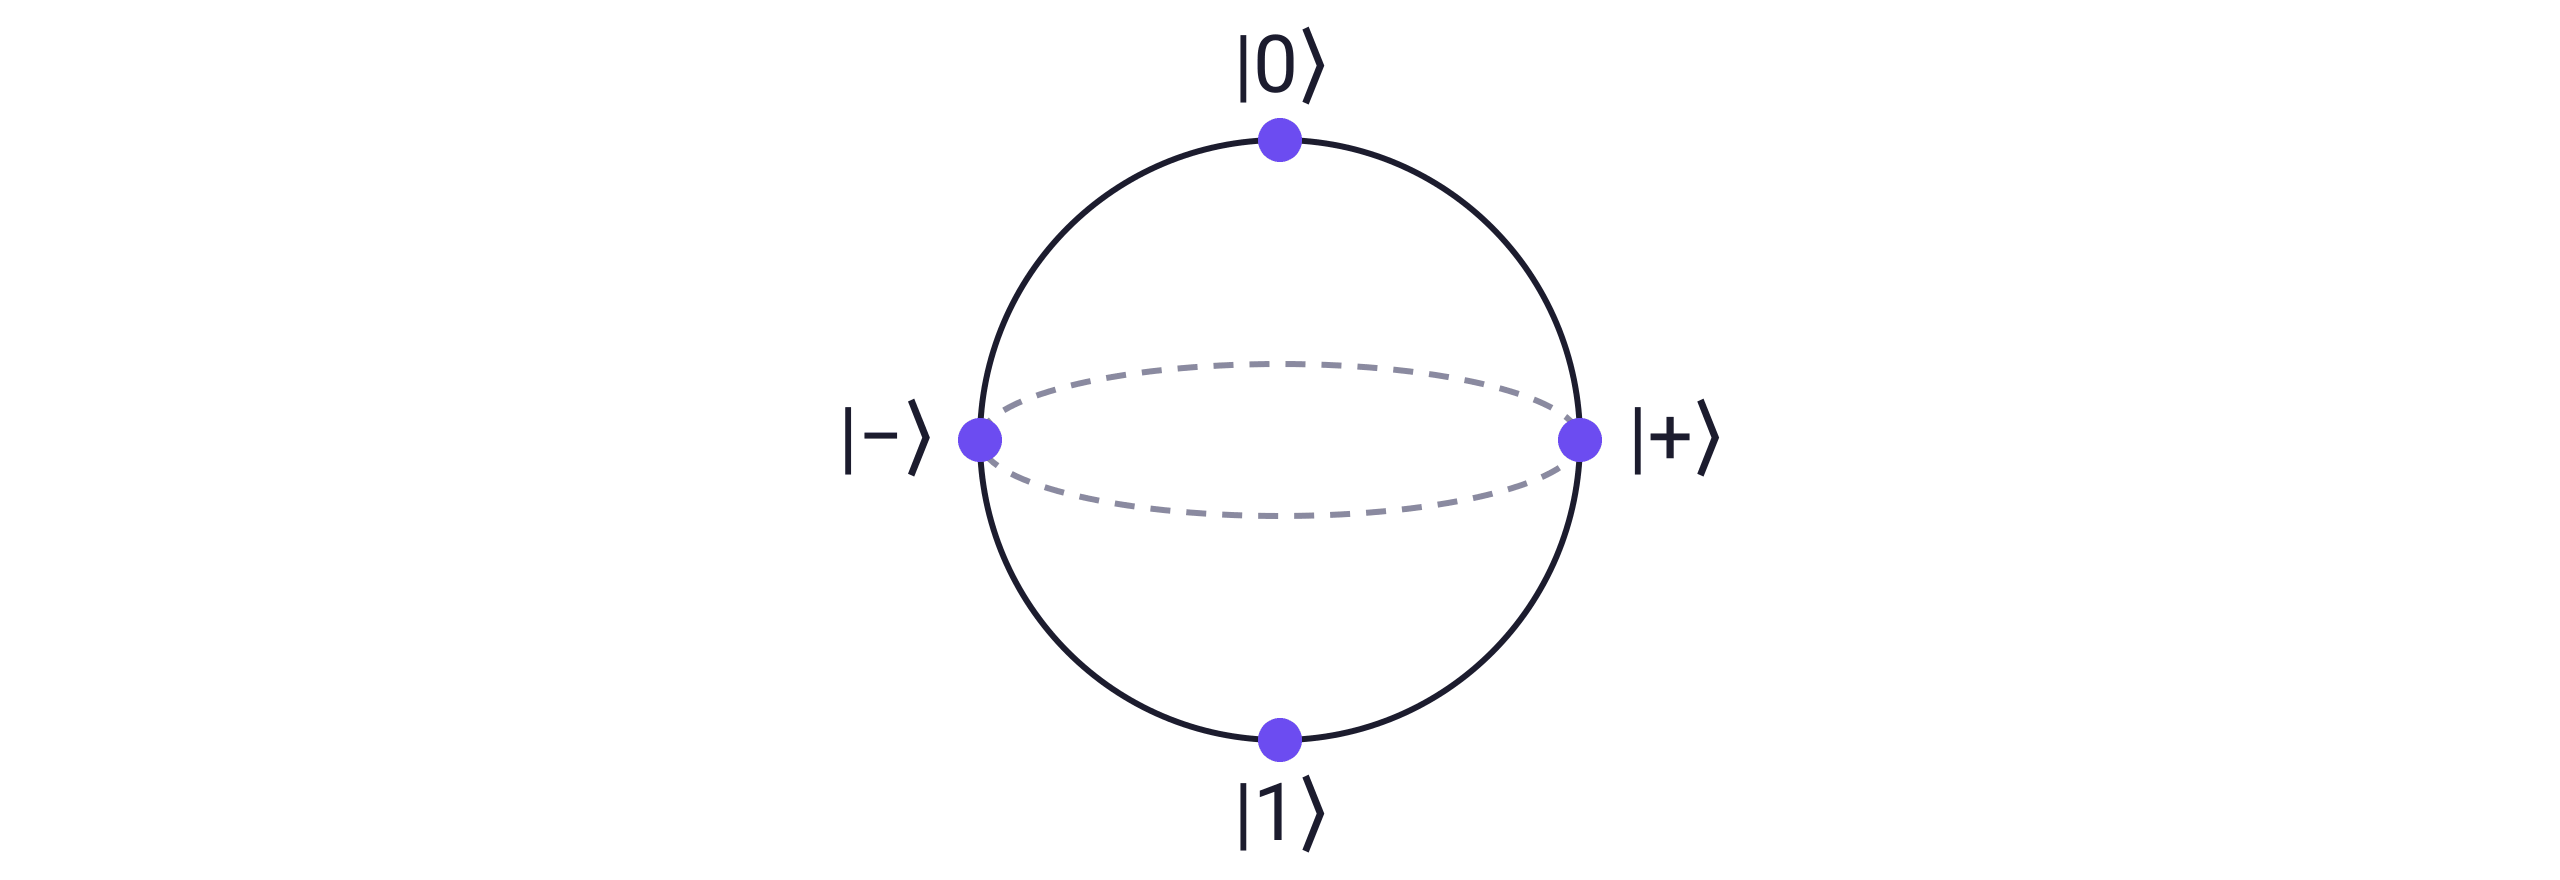

`QTensor.draw()` draws a single-qubit state on this sphere; the next cell shows $|+\rangle$. The drawing also labels $|{+i}\rangle$ and $|{-i}\rangle = (|0\rangle \pm i\,|1\rangle)/\sqrt2$ at the ends of the $Y$ axis; we do not need them today.

In [ ]:
# |+> points along the +X axis of the Bloch sphere
plus = QTensor.uniform(1)
plus.draw()

### Four reference states

The states $|0\rangle$ and $|1\rangle$ form the **$Z$ basis** (the computational basis), and $|+\rangle$ and $|-\rangle$ form the **$X$ basis**. The table gives their amplitudes and computational-basis measurement probabilities, where $P(0)$ and $P(1)$ mean the probabilities of observing 0 and 1.

| state | amplitudes $[\alpha, \beta]$ | $P(0)$ | $P(1)$ | Bloch location |
|---|---|---|---|---|
| $\lvert 0\rangle$ | $[1,\ 0]$ | $1$ | $0$ | north pole ($+Z$) |
| $\lvert 1\rangle$ | $[0,\ 1]$ | $0$ | $1$ | south pole ($-Z$) |
| $\lvert +\rangle$ | $\tfrac{1}{\sqrt2}[1,\ 1]$ | $\tfrac12$ | $\tfrac12$ | $+X$ (equator) |
| $\lvert -\rangle$ | $\tfrac{1}{\sqrt2}[1,\ -1]$ | $\tfrac12$ | $\tfrac12$ | $-X$ (equator) |

The last two rows have the same measurement probabilities but different relative phases. Their points on the sphere make that distinction visible. Part 2 introduces the Hadamard gate, an operation that lets us distinguish them by measurement. The code below prints each state's probabilities and draws its Bloch sphere.

In [ ]:
states = {
    "|0>": ket(0),
    "|1>": ket(1),
    "|+>": QTensor.uniform(1),
    "|->": (ket(0) - ket(1)).normalized(),
}

# |0> and |1> sit at the poles, |+> and |-> on the equator
for name, state in states.items():
    probabilities = state.probabilities()
    print(name, probabilities)
    state.draw()

## 1.2 · Measurement and the Born rule

Measuring a qubit in the computational basis returns a single classical bit, $0$ or $1$. For amplitudes $\alpha$ and $\beta$, the **Born rule** gives

$$P(0) = |\alpha|^2,\qquad P(1) = |\beta|^2.$$

Measurement **collapses** the state onto the observed basis state. Measuring it again in the same basis, without another intervening operation, returns the same value. To collect independent samples, prepare the original state again before each measurement. One preparation and measurement is called a **shot**; the `nshots` parameter sets how many to simulate.

Preparing $|+\rangle$ and measuring it gives an ideal fair coin, with probability $0.5$ for each result. Quantum random number generators (**QRNGs**) use physical quantum measurements as a source of randomness. Here we calculate the probabilities with `QTensor.probabilities()` and draw pseudorandom shots with `QTensor.sample()`, which counts how often each outcome came up. Part 2 simulates the preparation and measurement as a circuit; it also runs on a classical computer.

The next example compares the fair coin with a biased state. The real parameter $\theta$ sets its amplitudes to $\cos\theta$ and $\sin\theta$; at $\theta = \pi/6$ (30°), the amplitudes are $\sqrt3/2$ and $1/2$, so the probabilities are $0.75$ and $0.25$. This $\theta$ is half the Bloch-sphere angle from the previous section: the state sits at polar angle $2\theta$. In Part 2, a rotation gate needs angle $2\theta$ to give the same probabilities, and $R_Y(2\theta)$ prepares exactly this state from $|0\rangle$.

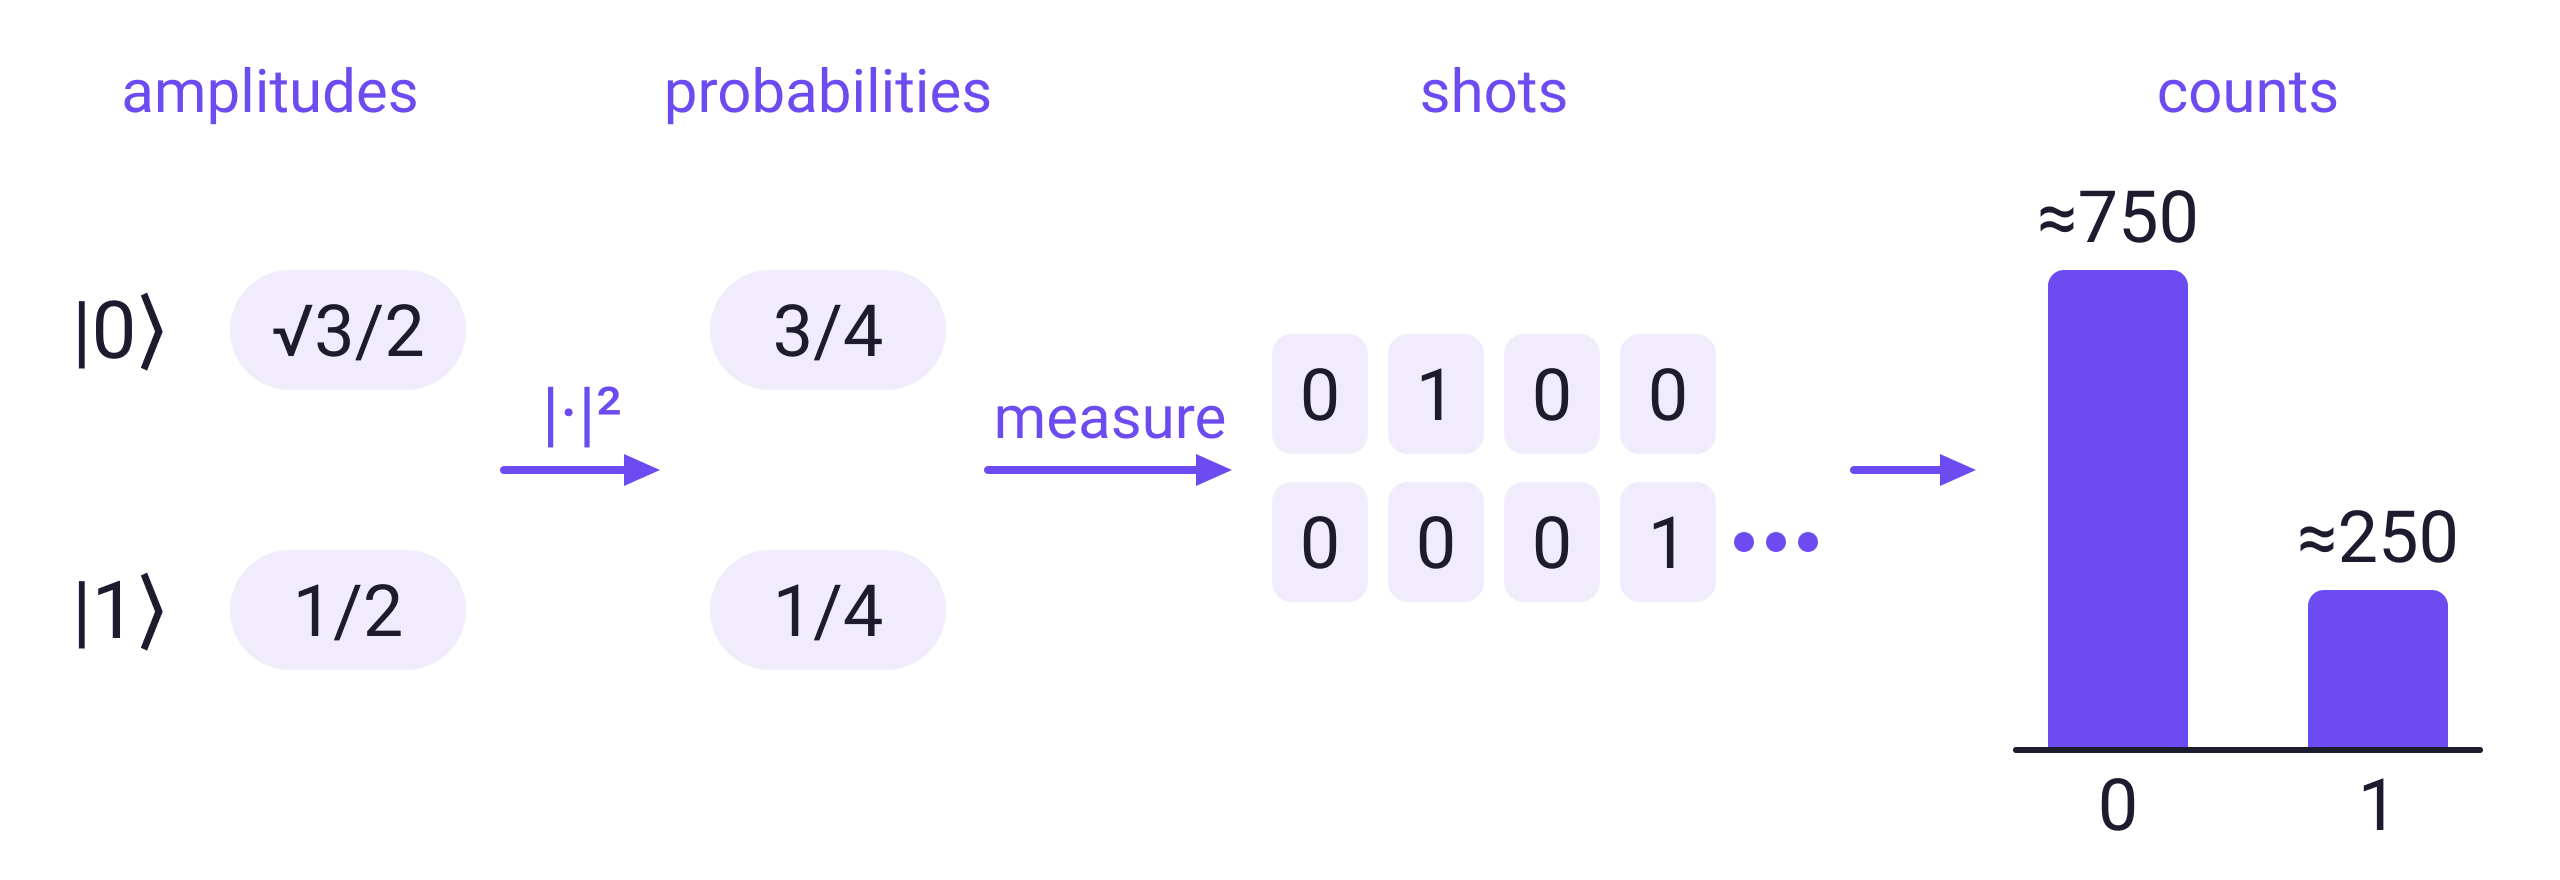

In [ ]:
# A fair coin. Floating-point rounding can print 0.5 as 0.4999999999999999.
plus = QTensor.uniform(1)
plus_probabilities = plus.probabilities()
print(plus_probabilities)

# A biased coin: scalar multiplication sets each amplitude
theta = np.pi / 6
biased = np.cos(theta) * ket(0) + np.sin(theta) * ket(1)
biased_probabilities = biased.probabilities()
print(biased_probabilities)

# Measure |+> 10 times; sample() counts how often each outcome came up
plus_samples = plus.sample(nshots=10)
print(plus_samples)

### 🧩 Exercise 1.1: build a loaded quantum coin

Choose the amplitudes of a single-qubit state so that the probability of measuring $1$ is **exactly 0.75**.

Use the real parameter $\theta$ to construct $|\psi(\theta)\rangle = \cos\theta\,|0\rangle + \sin\theta\,|1\rangle$. The Born rule gives $P(1) = \sin^2\theta$.

1. Choose `theta` so that $\sin^2\theta = 0.75$, either on paper or with NumPy.
2. Build the state from `ket(0)` and `ket(1)`, scaled by the corresponding amplitudes.
3. Use `probabilities()` to check for `[0.25, 0.75]`, allowing for floating-point rounding.
4. Sample 20 shots with `sample(nshots=20)`.

This reverses the earlier calculation: start with the probabilities you want and find amplitudes that produce them. The counts from 20 shots will usually differ from the exact proportions.

In [ ]:
theta = np.arcsin(...)
state = ... * ket(0) + ... * ket(1)
probabilities = ...
samples = ...

## 1.3 · Entanglement

A pure multi-qubit state is **entangled** if it cannot be written as a tensor product of single-qubit states. One example is the **Bell state**, denoted $|\Phi^+\rangle$:

$$|\Phi^+\rangle = \tfrac{1}{\sqrt 2}\big(|00\rangle + |11\rangle\big).$$

No pair of single-qubit states $|a\rangle = [a_0, a_1]$ and $|b\rangle = [b_0, b_1]$ satisfies $|\Phi^+\rangle = |a\rangle \otimes |b\rangle$. A product state has amplitudes $[a_0 b_0,\ a_0 b_1,\ a_1 b_0,\ a_1 b_1]$. Matching the Bell state would require $a_0 b_0 = a_1 b_1 = \tfrac{1}{\sqrt2}$, so all four coefficients would be nonzero. But it would also require $a_0 b_1 = a_1 b_0 = 0$, making at least one coefficient zero. These requirements contradict each other.

In computational-basis measurements of the Bell state, only `00` and `11` occur. Two parties holding one qubit each obtain the same random bit. By comparison, the unentangled state $|+\rangle \otimes |+\rangle$ assigns 25% probability to each of the four outcomes, so the two bits agree only half the time.

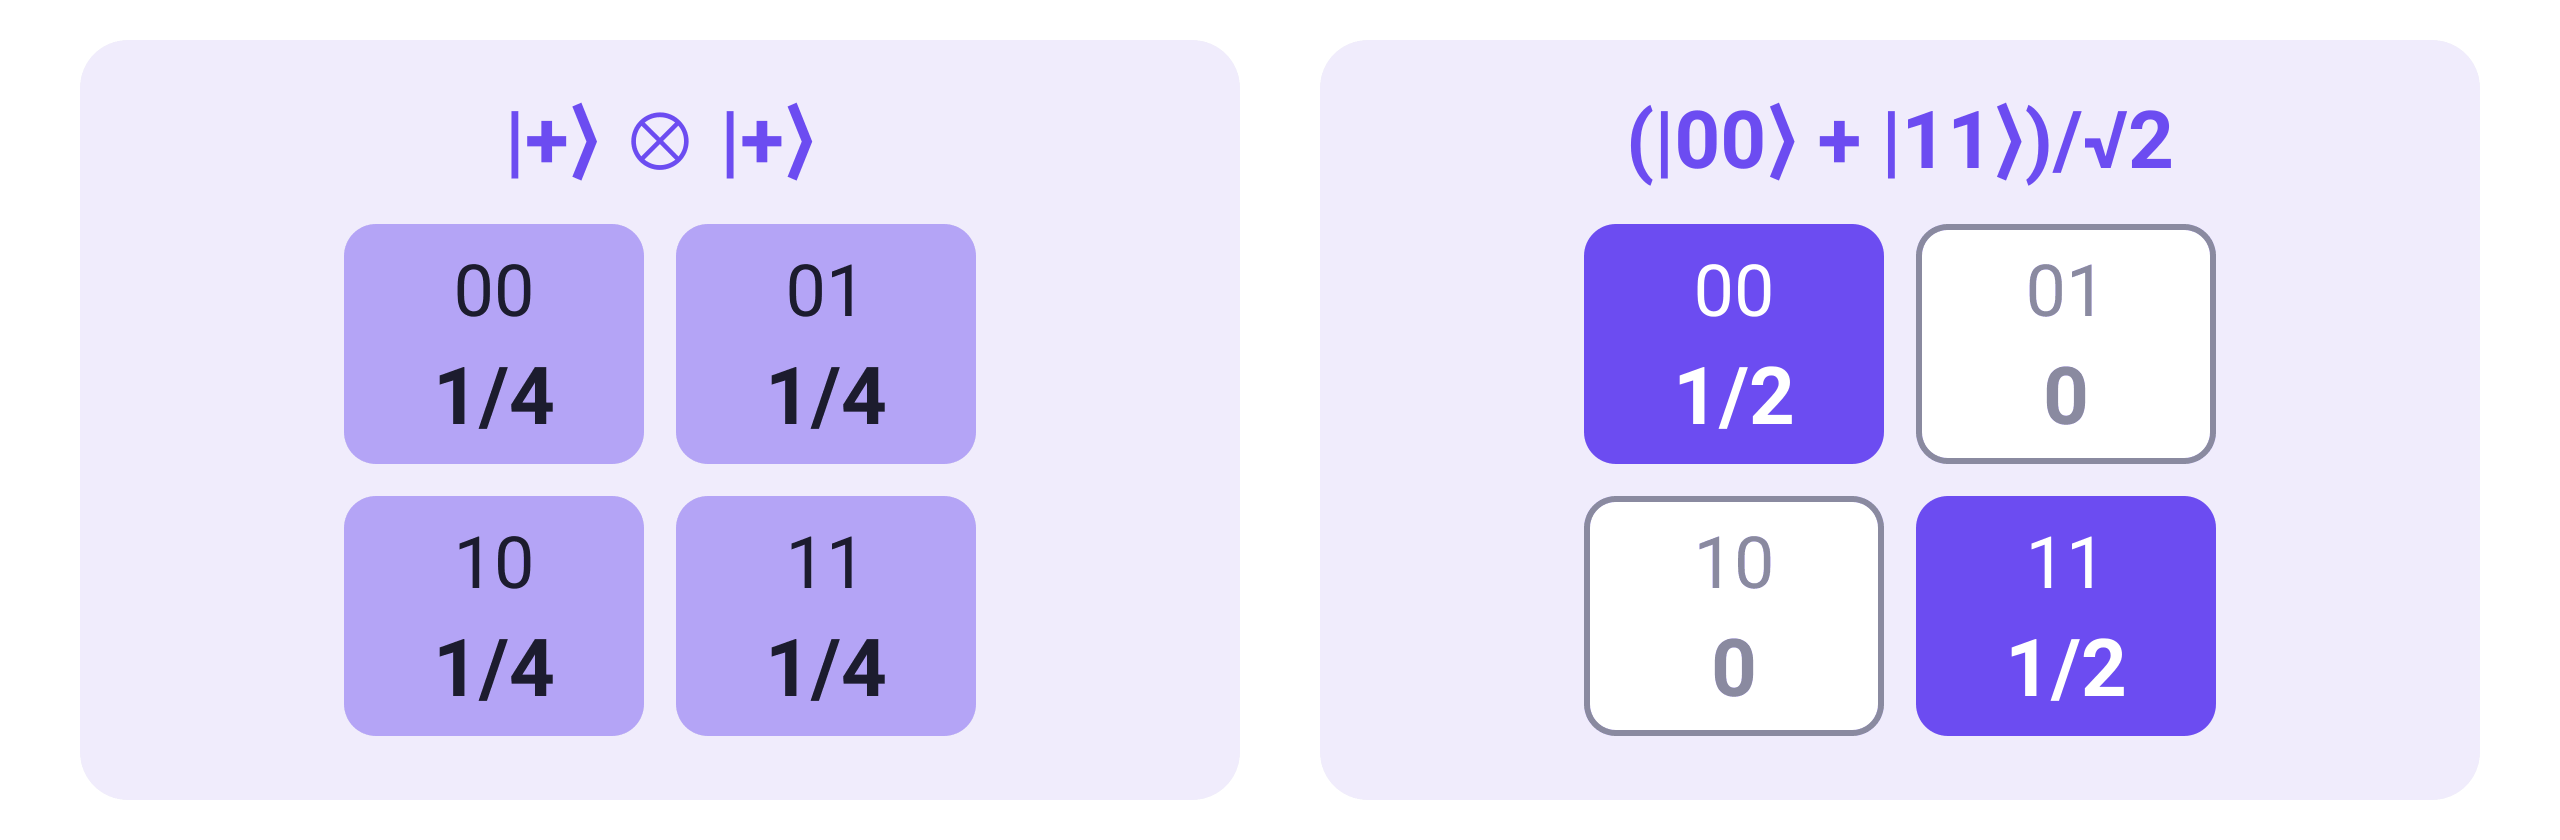

Matching bits do not prove entanglement: a coin flipped once and copied to both parties gives the same statistics. The difference shows in other bases. If both qubits of the Bell state are measured in the $X$ basis, the bits still always agree, while the copied coin gives all four outcomes equally often. Part 2 checks this with a circuit. Entanglement does not send messages either. Neither party chooses their bit, and each party's own results look like a fair coin, so the agreement only shows when they compare results.

Entanglement is a resource for some quantum key distribution (**QKD**) protocols, which share an encryption key in a way that reveals eavesdroppers. The best-known QKD protocol, BB84, uses single qubits rather than entangled pairs. Matching bits alone, however, do not demonstrate secrecy or rule out an eavesdropper; that requires a protocol beyond this example. Bell-test experiments, which measure at angles between these bases, showed that the correlations of entangled pairs cannot come from instructions the qubits carry from the start. They were recognized by the 2022 Nobel Prize in Physics.

The code compares the Bell and product states, then extends the example to three qubits with `ghz(3)`. **GHZ** stands for Greenberger–Horne–Zeilinger (Anton Zeilinger is one of the 2022 laureates): this family of states is an equal superposition of the all-zero and all-one basis states. `ghz(2)` gives the Bell state above, and `ghz(3)` gives only `000` or `111` when measured.

In [ ]:
# For 2 qubits, ghz() builds the Bell state. Probabilities are listed
# in the order 00, 01, 10, 11: only 00 and 11 can occur.
bell = ghz(2)
print(bell)
bell_probabilities = bell.probabilities()
print(bell_probabilities)

# Unentangled: each qubit is its own |+>, so all four outcomes are equally likely
plus = QTensor.uniform(1)
product = tensor_prod([plus, plus])
product_probabilities = product.probabilities()
print(product_probabilities)

# The 3-qubit GHZ state: only 000 and 111 can occur
ghz3 = ghz(3)
ghz3_probabilities = ghz3.probabilities()
print(ghz3_probabilities)

## Recap and what's next

A pure qubit state is a normalized vector of amplitudes. For $n$ qubits, a dense state vector has $2^n$ entries, but a computational-basis measurement returns one $n$-bit outcome. The Born rule connects amplitudes to outcome probabilities.

The states $|+\rangle$ and $|-\rangle$ illustrate why amplitudes contain more information than probabilities: their relative phases differ even though their computational-basis measurement probabilities agree. The Bell state illustrates entanglement, where the joint state cannot be factored into individual qubit states.

In **Part 2, Circuits / Digital Quantum Computing**, you will apply gates to these states, assemble and run circuits on `QiliSim`, and see interference change the measurement probabilities. The exercises build a shared random bit for three parties, then compare the cost of compiling a circuit for different chip layouts.